In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

import statsmodels.api as sm


In [2]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#En primer lugar, importamos los conjuntos x_train , x_test , y_test y_train conseguidos durante el preprocesamiento.ipynb
# x cuenta con las variables predictoras y e y con la variable a predecir (impago) 
#hemos usado estos conjuntos ya que están ya preparados para entrenar y evaluar el  modelo, ya que de lo contrario tendríamos que repetir todo el procespo previo




base_path = Path.cwd()

X_train = pd.read_csv(base_path / "X_train_impago.csv")
X_test = pd.read_csv(base_path / "X_test_impago.csv")

y_train = pd.read_csv(base_path / "y_train_impago.csv").squeeze("columns")
y_test = pd.read_csv(base_path / "y_test_impago.csv").squeeze("columns")

In [4]:
#comprobamos la distribucion de impago, para saber cómo se distribuye el dataset(tanto en train como en test) con el objetivo de conocer si ambas clases tienen una presencia similar
#  Cómo se puede observar, el dataset está bastante desbalanceado, teniendo un 84,4% de no impago y un 11,5 % de impago
#una vez sabido esto,lo cual nos ayudará a la hora de interpretar las métricas del modelo, podemos comenzar a entrenar el modelo

 
print("\nPorcentaje de observaciones por clase en train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nPorcentaje de observaciones por clase en test:")
print(y_test.value_counts(normalize=True) * 100)


Porcentaje de observaciones por clase en train:
Impago
0    88.447976
1    11.552024
Name: proportion, dtype: float64

Porcentaje de observaciones por clase en test:
Impago
0    88.449789
1    11.550211
Name: proportion, dtype: float64


In [5]:
#también analizaremos la correlación entre la variable objetivo y las variables predictoras 
#saber la relación lineal que tiene cada variable con el impago nos servirá como primer análisis antes de hacer la regresión

# Analizamos la correlación entre la variable objetivo Impago y las variables predictoras.
# Realizamos este análisis para conocer la relación lineal que presenta cada variable
# con el impago y observar cuáles muestran una mayor asociación positiva o negativa.
# Esto nos sirve como un primer análisis de la relación entre las variables antes de
# entrenar la regresión logística.

datos_correlacion = X_train.copy()
datos_correlacion["Impago"] = y_train.values

correlaciones = (
    datos_correlacion
    .corr()["Impago"]
    .drop("Impago")
    .sort_values(ascending=False)
)

print(correlaciones)




Ratio_Interes                   0.126984
Estado_Civil_Soltero            0.105324
Estudios_Grado Universitario    0.022679
Posesion_Hipoteca_1.0           0.009151
Estudios_Máster                 0.003939
Num_Creditos                    0.000268
Duracion                       -0.006971
Prima                          -0.018751
Ratio_Deuda_Ingresos           -0.024650
Estudios_Escolar               -0.028209
Scoring_Crediticio             -0.041950
Monto_Inicial                  -0.050373
Estado_Civil_Divorciado        -0.055359
Ingresos                       -0.084079
Meses_Empleo                   -0.162833
Edad                           -0.167416
Name: Impago, dtype: float64


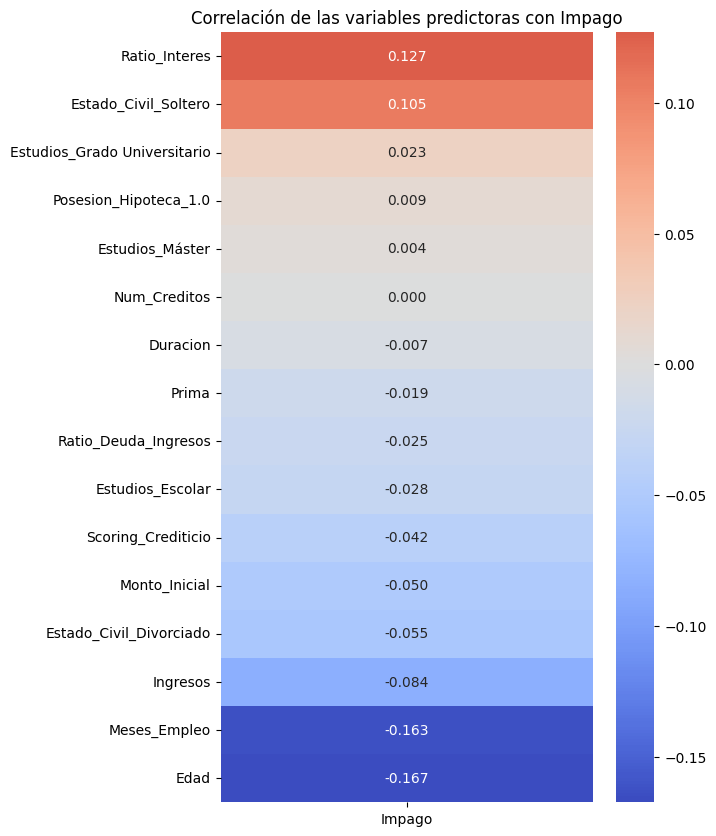

In [6]:
#vistos los resultados podemos obtener ciertas conclusiones así como que existe cierta correlación positiva con ciertas variables , así como el ratio de interés o el estado civil de la persona, por lo que a medida de que esa variable aumente , tiende a aumentar el impago.
#por otro lado, también existe cierta correlación negativa con variables como la edad o los meses de empleo, por lo que a medida que aumenta esa variable el impago tiende a disminuir
#visualizamos los resultados con un gráfico
# Representamos gráficamente las correlaciones para facilitar su interpretación.
import seaborn as sns
import matplotlib.pyplot as plt

correlaciones = correlaciones.sort_values(ascending=False).to_frame(name="Impago")

# Mapa de calor
plt.figure(figsize=(6, 10))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Correlación de las variables predictoras con Impago")
plt.show()


In [7]:
#una vez los datos están listos, usaremos sklearn para crear y entrenar el modelo
#para estimare la probabilidad de impago, usaremos la regresión logística, ya que la variable impago es binaria(0=no impago 1= impoago)
#y este modelo permite estimar la probabilidad de pertenecer a una o a otra clase
#usaremos fit para que a partir de x_train y de y_train el modelo aprenda la relación entre las variables que se usan para predecir y entre la probabilidad de impago
modelo_log_sklearn = LogisticRegression()

modelo_log_sklearn.fit(X_train, y_train)




,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [8]:
#una vez entrenado el modelo, vamos a ver información del modelo, así como el intercepto y los coeficientes obtenidos
#gracias a esto podemos conocer qué variables aumentan o disminuyen la probabilidad de impago y conocer su relación con la variable objetivo
#también obtenemos el accuracy obtenida por el modelo sobre los datos del entrenamiento, lo cual nos sirve para conocer qué  proporción de train han sido clasificadaas adecuadamente 
#aun así , como hemos visto antes, existe un gran desbalance entre el impago y el no impago,por lo que el acuraccy no será sufuiciente para saber si el modelo es adecuado y usaremos metricas como el recall , precision o f1-score



print("\nIntercepto:")
print(modelo_log_sklearn.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X_train.columns,
    "Coeficiente": modelo_log_sklearn.coef_.flatten()
})

print("\nCoeficientes:")
print(coeficientes)


print(
    "\nAccuracy de entrenamiento:",
    modelo_log_sklearn.score(X_train, y_train))


Intercepto:
[-2.33601145]

Coeficientes:
                        Variable  Coeficiente
0                   Num_Creditos    -0.000396
1                          Prima     0.005377
2                  Monto_Inicial    -0.023371
3                   Meses_Empleo    -0.269188
4                       Duracion    -0.023597
5             Scoring_Crediticio    -0.121507
6           Ratio_Deuda_Ingresos    -0.053486
7                  Ratio_Interes     0.411211
8                           Edad    -0.341578
9                       Ingresos     0.031602
10              Estudios_Escolar     0.151676
11  Estudios_Grado Universitario     0.078845
12               Estudios_Máster     0.013495
13       Estado_Civil_Divorciado    -0.019647
14          Estado_Civil_Soltero     0.007270
15         Posesion_Hipoteca_1.0     0.048691

Accuracy de entrenamiento: 0.8843985115130243


Realizamos predicciones probabilísticas:

- Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

- Con .predict() se obtiene, para cada observación, la clasificación predicha por el modelo. Esta clasificación se corresponde con la clase con mayor probabilidad.

In [9]:
#una vez entrenado el modelo, lo utilizamos para conocer la probabilidad de que cada observación de test pertenezca a pago o a impago
#para ello usaremos predict_proba,la cual da probabilidad predicha de pertenecer a cada una de las dos clases.
#gracias a esto podemos conocer el nivel de riesgo de impago de cada cliente
probabilidades = modelo_log_sklearn.predict_proba(X_test)

probabilidades = pd.DataFrame(
    probabilidades,
    columns=modelo_log_sklearn.classes_
)

print("\nPrimeras probabilidades:")
print(probabilidades.head())





Primeras probabilidades:
          0         1
0  0.925994  0.074006
1  0.780709  0.219291
2  0.922595  0.077405
3  0.864693  0.135307
4  0.847288  0.152712


In [13]:

# Nos quedamos con la probabilidad de Impago(1), ya que de esa forma obtenemos una probabilidad concreta de impago para cliente, lo cual será interesante para analizar su riesgo o clasificarlo posteriormente

prob_impago = probabilidades[1]

#tambiénm vamos a transformar las probabilidades en una clasificación de 0 a 1, poniendo un thresold de 0,5 es decir, aquellos usuarios con probabilifdad de impago inferior al 50% serán clasificados como no impago
#mientras que aquellos que tengan una probabilidad de impago igual o mayor que el 50% serán clasificados como impago
#gracias a esto luego podremos comparar las predicciones del modelo con los valores reañes de y_test 
clasificacion = np.where(prob_impago < 0.5, 0, 1)

print("Primeras clasificaciones:")
print(clasificacion[:10])

Primeras clasificaciones:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
#también ajustamos la regresión logística usando statsmodels, ya que nos permite obtener información estadística más detallada sdobre el modelo(r2,std err...)
#ademas, podremnos conocer qué variables contribuyen a explicar el impago
# Statsmodels necesita que todas las variables sean numéricas
X_train_stats = X_train.astype(float)

# Añadir constante para calcular el intercepto
X_train_stats = sm.add_constant(X_train_stats, prepend=True)

modelo_log_statsm = sm.Logit(
    endog=y_train,
    exog=X_train_stats
)

modelo_log_statsm = modelo_log_statsm.fit()

print("\nResumen del modelo:")
print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.333540
         Iterations 7

Resumen del modelo:
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                61539
Model:                          Logit   Df Residuals:                    61522
Method:                           MLE   Df Model:                           16
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                 0.06807
Time:                        00:47:29   Log-Likelihood:                -20526.
converged:                       True   LL-Null:                       -22025.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -2.3346      0.071 

In [15]:
#calculamos el intervalos de confianza de los coeficientes(95% del modelo)
#gracias a esto conocemos el rango de valores dentro del cual se espera que esté el coeficiente de verdad de cada predictor

intervalos_ci = modelo_log_statsm.conf_int(alpha=0.05).rename(columns={0: "2.5%", 1: "97.5%"})

intervalos_ci

,2.5%,97.5%
const,-2.473328,-2.195849
Num_Creditos,-0.025821,0.025019
Prima,-0.039777,0.050256
Monto_Inicial,-0.066773,0.021871
Meses_Empleo,-0.389982,-0.153239
Duracion,-0.052315,0.005232
Scoring_Crediticio,-0.148783,-0.094664
Ratio_Deuda_Ingresos,-0.093946,-0.014105
Ratio_Interes,0.385367,0.437352
Edad,-0.446805,-0.227427


In [22]:
#creamos una tabla con los principales resultados de cada variable 
#metemos el coeficiente , el p-valor, y el intervalo de confianza del 95%
tabla= pd.DataFrame({
    "Variable": modelo_log_statsm.params.index,
    "Coeficiente": modelo_log_statsm.params.values,
    "p-valor": modelo_log_statsm.pvalues.values,
    "IC 2,5 %": modelo_log_statsm.conf_int()[0].values,
    "IC 97,5 %": modelo_log_statsm.conf_int()[1].values
})

tabla.head(15)

,Variable,Coeficiente,p-valor,"IC 2,5 %","IC 97,5 %"
0,const,-2.334588,1.542980e-238,-2.473328,-2.195849
1,Num_Creditos,-0.000401,9.753240e-01,-0.025821,0.025019
2,Prima,0.005240,8.195530e-01,-0.039777,0.050256
3,Monto_Inicial,-0.022451,3.208137e-01,-0.066773,0.021871
4,Meses_Empleo,-0.271610,6.883584e-06,-0.389982,-0.153239
5,Duracion,-0.023542,1.088045e-01,-0.052315,0.005232
6,Scoring_Crediticio,-0.121724,1.179455e-18,-0.148783,-0.094664
7,Ratio_Deuda_Ingresos,-0.054026,7.990363e-03,-0.093946,-0.014105
8,Ratio_Interes,0.411359,3.020168e-211,0.385367,0.437352
9,Edad,-0.337116,1.704555e-09,-0.446805,-0.227427


METRICAS DE RENDIMIENTO